# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [28]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.
Outcome : salary_k_eur , predictor : training_hours, expected direction : positive, plausible omitted variable : ai_tool_use

In [29]:
df[["salary_k_eur", "training_hours", "ai_tool_use"]].describe().round(2)

,salary_k_eur,training_hours,ai_tool_use
count,240.00,240.00,240.00
mean,75.68,39.68,6.44
std,15.68,16.09,2.22
min,36.20,0.00,0.70
25%,64.72,28.95,4.97
50%,74.45,39.30,6.50
75%,86.52,49.82,8.00
max,119.80,90.00,10.00


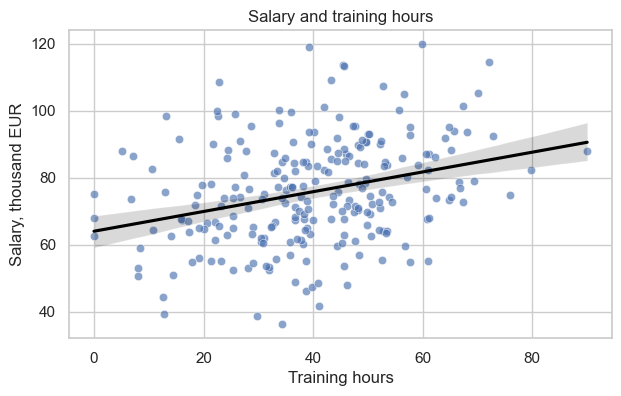

In [30]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")
plt.show()

In [31]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     26.80
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           4.80e-07
Time:                        02:15:26   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.511     25.

In [32]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Average salary difference per additional training hour: {slope:.3f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Average salary difference per additional training hour: 0.295 thousand EUR


In [33]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
prediction = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(prediction).round(1)

,training_hours,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,10,66.9,2.0,63.0,70.8,37.3,96.5
1,40,75.8,1.0,73.9,77.7,46.4,105.2
2,80,87.6,2.4,82.8,92.4,57.8,117.3


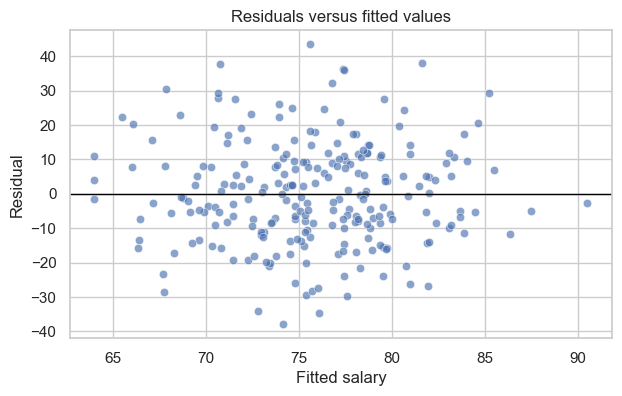

In [34]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")
plt.show()

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

On average, per year, workers who do one more hour of training earn 295 euro more. 95 % confidence interval is 183 to 407 euro per training hour, so I would conclude that link is clearly positive. This is an association not a direct proof that training raises salary. But the link between hours of traing and salary rise is weak. Training hours explain only 9 % of differences in salary. The other 91% of difference comes from other factors. 
People who train more may also use ai tools more and ai tools can be the reason for increasing salary. If that was one reasons, then 295 euro increase would not only be because of training, but some part of 295 will be result of ai usage. 